# Prediction Indonesia Adjusted net national income per capita

Disini kita mengambil dataset dari the world bank link : https://data.worldbank.org/indicator/NY.ADJ.NNTY.PC.CD 
berikut screenshot dari grafik perkembagan adjusted net national income per capita tahunan dunia
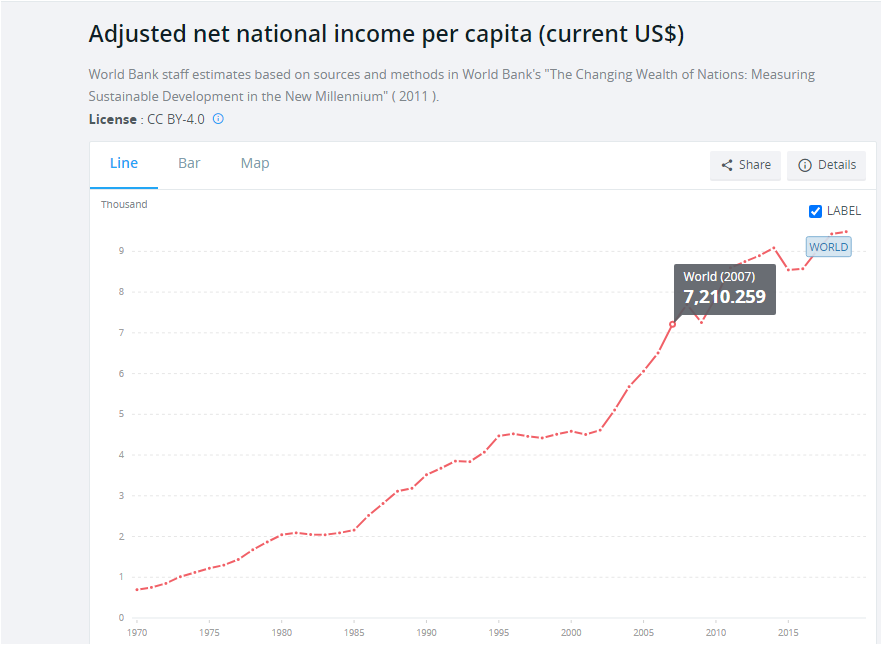
Dataset yang digunakan adalah Pendapatan nasional bersih per kapita tahunan di negara di dunia dalam dolar US.
Dataset ini memiliki memiliki 263 baris dan 66 kolom kolom  yang berisi data mengenai nama negara, kode negara, dan info lainnya serta pendapatan bersih perkapita dari tahun 1960-2021 yang berupa data float atau data berkoma.
disini kita hanya akan mengambil data yang berasal dari negara kita indonesia, untuk dianalisis dan melakukan prediksi menggunakan regresi untuk mengetahui income per capita tahunan di masa mendatang

"Kita import beberapa library (pandas, seaborn, dan matplotlib.pyplota) yang akan digunakan dengan mempersingkat panggilannya"

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

"Mengambil file yang bernama 'per capita income in world.csv' dari home yang telah di upload sebelumnya"

In [2]:
df = pd.read_csv('per capita income in world.csv')

"Melihat identifikasi index yang ada pada file yang akan di gunakan"
"ada 4 kolom yang berisi 205 data objek/str dan 62 kolom berisi data float"

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            74 non-null     float64
 15  1971            106 non-null    float64
 16  1972            106 non-null    float64
 17  1973            108 non-null    flo

"Melihat banyak baris dan kolom pada file"
"Terdapat 266 baris dan 67 kolom"

In [4]:
df.shape

(266, 65)

"Untuk melihat semua data"

In [5]:
df

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,19940.338266,21072.154089,22106.983018,23123.013898,24173.603629,24120.101723,24584.121098,25021.539233,NaN,NaN
1,Africa Eastern and Southern,AFE,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1330.114196,1320.668936,1308.999780,1323.507871,1240.793002,1165.048286,1272.320550,1277.651690,1247.704898,1110.500829
2,Afghanistan,AFG,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,540.130209,584.875040,573.372758,564.388375,516.822931,478.688330,486.034778,452.362622,463.843374,475.620362
3,Africa Western and Central,AFW,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1358.413217,1472.463728,1661.209362,1748.768673,1592.424639,1413.997327,1326.239125,1370.955579,1442.269355,1406.951825
4,Angola,AGO,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2382.861462,2844.395531,3174.474885,3608.617334,3226.929799,2717.739006,2975.447502,2082.698449,1766.910438,1122.792517
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1031.551750,1183.495514,1367.845733,1422.192041,1470.154386,1095.666047,916.302214,720.005151,NaN,NaN
263,South Africa,ZAF,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,7141.832624,6717.093355,6061.654268,5721.229123,5190.070684,4706.022503,5495.603989,5742.782971,5420.513758,4603.515007
264,Zambia,ZMB,Adjusted net national income per capita (curre...,NY.ADJ.NNTY.PC.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1208.040294,1374.877013,1443.078990,1409.720517,1079.111053,1017.367016,1174.971056,1177.818038,1018.925034,754.990811


"kita cek data kosong padadataframe "

In [6]:
df.isna().sum()

Country Name        0
Country Code        0
Indicator Name      0
Indicator Code      0
1960              266
                 ... 
2016               40
2017               40
2018               39
2019               45
2020               48
Length: 65, dtype: int64

"Untuk mempermudah kita hapus saja kolom 'Country Code','Indicator Name','Indicator Code' dan data pada tahun 1960-1969 karena  datanya kosong serta kolom 2020 dan 2021 yang semuanya kosong karena belum didata "

In [7]:
df=df.drop(columns=['Country Code','Indicator Name','Indicator Code','1960','1961','1962','1963','1964','1965','1966','1967','1968','1969'])
df

,Country Name,1970,1971,1972,1973,1974,1975,1976,1977,1978,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19940.338266,21072.154089,22106.983018,23123.013898,24173.603629,24120.101723,24584.121098,25021.539233,NaN,NaN
1,Africa Eastern and Southern,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1330.114196,1320.668936,1308.999780,1323.507871,1240.793002,1165.048286,1272.320550,1277.651690,1247.704898,1110.500829
2,Afghanistan,148.475815,151.336936,128.629846,135.421467,163.884208,174.810508,184.766102,209.999771,231.703234,...,540.130209,584.875040,573.372758,564.388375,516.822931,478.688330,486.034778,452.362622,463.843374,475.620362
3,Africa Western and Central,194.197445,136.926342,162.445925,193.286110,243.565575,291.861364,351.436041,351.163052,380.898566,...,1358.413217,1472.463728,1661.209362,1748.768673,1592.424639,1413.997327,1326.239125,1370.955579,1442.269355,1406.951825
4,Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2382.861462,2844.395531,3174.474885,3608.617334,3226.929799,2717.739006,2975.447502,2082.698449,1766.910438,1122.792517
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1031.551750,1183.495514,1367.845733,1422.192041,1470.154386,1095.666047,916.302214,720.005151,NaN,NaN
263,South Africa,NaN,753.114590,764.587948,1029.095462,1242.747154,1218.882559,1114.827419,1194.422756,1341.293782,...,7141.832624,6717.093355,6061.654268,5721.229123,5190.070684,4706.022503,5495.603989,5742.782971,5420.513758,4603.515007
264,Zambia,NaN,272.302136,293.321017,280.056992,418.248973,367.063306,356.514750,334.703312,374.777413,...,1208.040294,1374.877013,1443.078990,1409.720517,1079.111053,1017.367016,1174.971056,1177.818038,1018.925034,754.990811


"Untuk mempermudah pemanggilan maka kolom 'Country Name' kita ubag manjadi country"

In [8]:
df.rename(columns={'Country Name':'country'}, inplace=True)

"Karena kita hanya akan menganalisis prediksi pendapatan perkapita di indonesia, maka kita buat dataframe baru dengan nama df_ind yang hanya menampung data dari negara indonesia"

In [9]:
df_ind=df[df.country=='Indonesia']
df_ind

,country,1970,1971,1972,1973,1974,1975,1976,1977,1978,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
106,Indonesia,72.928744,72.095377,80.483044,113.996602,158.871418,187.37429,225.676894,265.466169,295.238193,...,2691.080749,2770.447721,2727.837767,2626.136342,2560.324843,2819.749588,3036.098574,3079.57003,3284.667997,3091.998317


"Untuk mempermudah kita hapus saja kolom country"

In [10]:
df_ind_1=df_ind.drop(columns=['country'])
df_ind_1

,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
106,72.928744,72.095377,80.483044,113.996602,158.871418,187.37429,225.676894,265.466169,295.238193,242.084969,...,2691.080749,2770.447721,2727.837767,2626.136342,2560.324843,2819.749588,3036.098574,3079.57003,3284.667997,3091.998317


"Untuk mepermudah kita buat dataframe baru yang mengubah dataframe df_ind dengan berurut ke bawah"

In [11]:
ind=df_ind_1.melt(var_name='year',
            value_name='income')
ind

,year,income
0,1970,72.928744
1,1971,72.095377
2,1972,80.483044
3,1973,113.996602
4,1974,158.871418
5,1975,187.374290
6,1976,225.676894
7,1977,265.466169
8,1978,295.238193
9,1979,242.084969


"Melihat rangkuman statistik pada data yang ada di dalam file Mulai dari banyak data, rata2, standar deviasi dan lainnya"

In [12]:
ind.describe()

,income
count,51.000000
mean,1057.245433
std,1001.372067
min,72.095377
25%,401.908929
50%,585.347753
75%,1437.762210
max,3284.667997


"kita cek terlebih dahulu type data pada data frame"

In [13]:
ind.dtypes

year       object
income    float64
dtype: object

"Karena kolom year type datanya object/str maka kita harus ubah terlebih dahulu menjadi integer

In [14]:
ind=ind.astype({'year':'int'})

"kemudian kita cek kembali dan type data year telah berubah menjadi integer"

In [15]:
ind.dtypes 

year        int32
income    float64
dtype: object

Melihat boxplot dari pendapatan perkapita di indonesia

<AxesSubplot: >

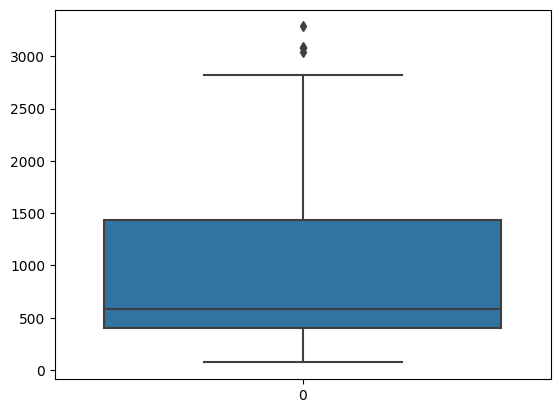

In [16]:
sns.boxplot(ind.income)

<AxesSubplot: xlabel='year', ylabel='income'>

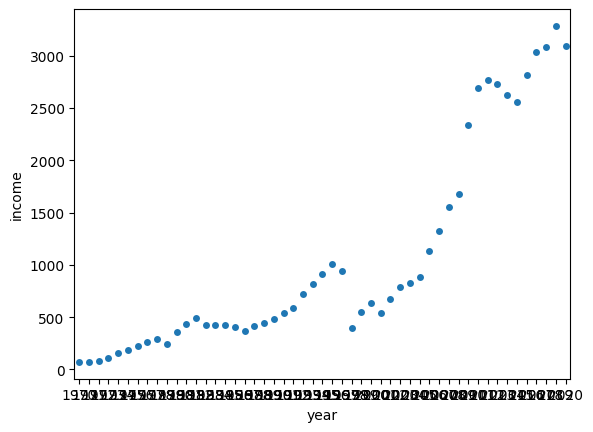

In [17]:
sns.stripplot(x=ind.year, y=ind.income)

"Melihat histogram"

<AxesSubplot: >

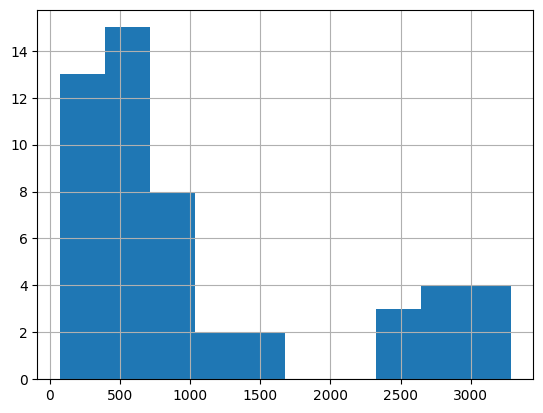

In [18]:
ind.income.hist()

"Menampilkan bagaimana grafik perbandingan pendapatan di indonesia dari tahun 1970 - 2019 "

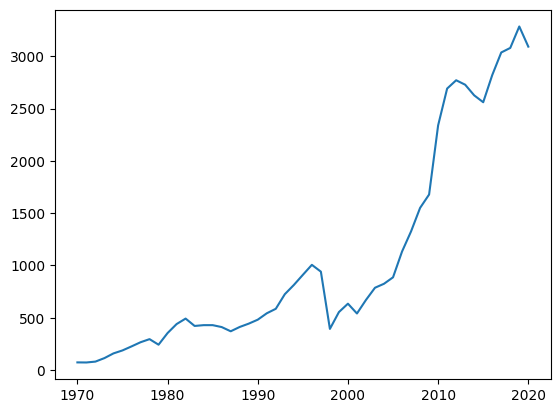

In [19]:
plt.plot(ind.year, ind.income)
plt.show()

"Mengambil data year yang di berikan pada X dan data income pada Y"

In [20]:
X=ind.iloc[:, :-1]
Y=ind.iloc[:, 1]

"kita import library train_test_split untuk split data train dan data test"
"kita identifikasikan data train dan test pad X dan Y dengan rasio 30% data test dan 70% data training"
"data untuk test dan train tetap dan tidak berubah maka dibuta randome_state=0"

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=3/10, random_state=0)

"kita import library LinearRegression untuk melihar regresi dari data"

In [22]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

"Menampilkan grafik regresi untuk data train dengan modul matplotlib.pyplot "
"sumbu x dalam year dan sumbu y sebagai pendapatan"

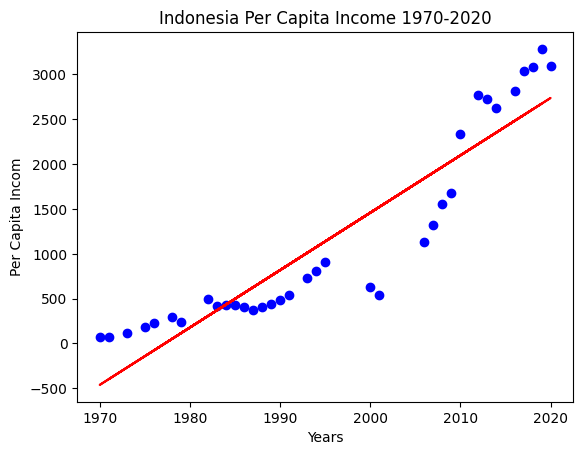

In [23]:
plt.scatter(X_train, y_train, color="blue")
plt.plot(X_train, regressor.predict(X_train), color="red")
plt.title("Indonesia Per Capita Income 1970-2020")
plt.xlabel("Years")
plt.ylabel("Per Capita Incom")
plt.show()

"Menampilkan grafik regresi untuk data test dengan modul matplotlib.pyplot "
"sumbu x dalam year dan sumbu y sebagai pendapatan"

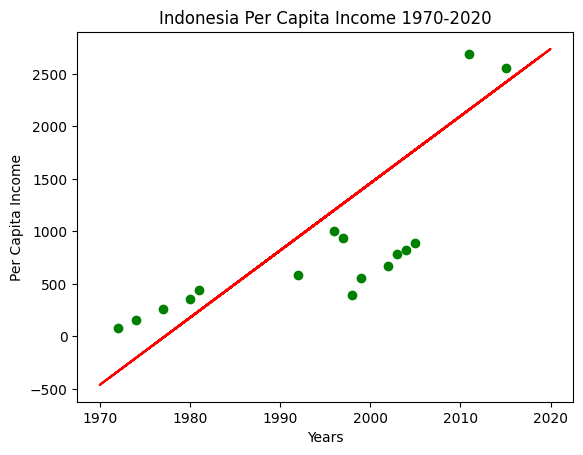

In [24]:
plt.scatter(X_test, y_test, color="green")
plt.plot(X_train, regressor.predict(X_train), color="red")
plt.title("Indonesia Per Capita Income 1970-2020")
plt.xlabel("Years")
plt.ylabel("Per Capita Income")
plt.show()

"Kita buat fungsi prediksi untuk pendapatan berdasarkan nilai regresi dari data"

In [25]:
y_pred = regressor.predict(X_test)

"Melihat Prediksi Jumlah pendapatan perkapita pada tahun yang akan datang"
, kita menggunakan error handling untuk mengantisipasi kesalahan masukkan yang akan diminta, errror handling yang digunakan adalah ValueError

In [26]:
try:
    n=int(input("Masukkan Tahun : "))
except ValueError:
    print("Masukkan Harus Berupa Angka ! !")
if n>2020 :
    Income_pred = regressor.predict([[n]])
    print("Jumlah pendapatan perkapita di Indonesia pada tahun {} adalah sekitar $".format(n),int(Income_pred))
    print("Atau dalam rupiah sekitar Rp.",int(Income_pred*14224.90))
else :
    print("Tahun harus lebih dari 2020")
    

" Dari hasil analisis data2 pendapatan perkapita di indonesia dari tahun 1970 hingga 2020, kita dapat memprediksi besarnya pendapatan perkapia tahunan pada tahun 2050 adalah 4658 dolar US atau setelah dikonversi ke rupiah sekitar Rp. 66.259.975 "

link vidio presentasi : https://drive.google.com/drive/folders/1xcCi9vEh5GLF8nnxe83NRDkhbbYZBc4P?usp=sharing